# Градиентный бустинг: insurance

Задача 6 ЛР5: CatBoost, LightGBM, XGBoost и бустинг из sklearn на insurance. Регрессия `charges` и классификация дорогих клиентов.

Split 80/20 с `random_state=42`, как в [insurance_regression](insurance_regression.ipynb), поэтому test совпадает и OLS сравнивается напрямую. Модели, гиперпараметры и порог классификации выбираются по 5-fold CV на train. Test используется один раз, в конце каждой части.

[Методы и результаты](../docs/classic-ml.md) · [Источники](../PROVENANCE.md)

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import optuna
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, CatBoostRegressor, Pool
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, mean_absolute_error, mean_squared_error,
                             precision_recall_curve, precision_score, r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

REPO_DIR = Path.cwd()
if REPO_DIR.name == "notebooks":
    REPO_DIR = REPO_DIR.parent
RESULTS = REPO_DIR / "results"
SEED = 42

url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

NUM = ["age", "bmi", "children"]
CAT = ["sex", "smoker", "region"]
X, y = df[NUM + CAT], df["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"train {X_train.shape}, test {X_test.shape}")

train (1070, 6), test (268, 6)


## 1. EDA на Polars

Средние расходы на train по статусу курения и ожирению (BMI ≥ 30).

In [2]:
(pl.from_pandas(X_train.assign(charges=y_train))
 .with_columns((pl.col("bmi") >= 30).alias("obese"))
 .group_by("smoker", "obese")
 .agg(pl.len().alias("n"),
      pl.col("charges").mean().round(0).alias("mean_charges"),
      pl.col("charges").median().round(0).alias("median_charges"))
 .sort("smoker", "obese"))

smoker,obese,n,mean_charges,median_charges
str,bool,u32,f64,f64
"""no""",false,407,8056.0,6878.0
"""no""",true,443,9059.0,8458.0
"""yes""",false,105,21007.0,19965.0
"""yes""",true,115,41592.0,40721.0


Средние расходы без курения: 8,1 тыс. при BMI < 30 и 9,1 тыс. при BMI ≥ 30. У курящих: 21,0 тыс. и 41,6 тыс. Проверяем взаимодействие smoker × BMI, которого нет в исходной линейной модели.

## 2. Регрессия: OLS и бустинги без настройки

Метрика — RMSE. У моделей одинаковые folds. LightGBM, XGBoost и HistGradientBoosting получают категории как `category`, CatBoost — как строки.

In [3]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)


def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5


def as_category(X):
    return X.astype({c: "category" for c in CAT if c in X})


def cv_rmse(make_model, X, y, prep=lambda X: X):
    scores = []
    for tr, va in kf.split(X):
        model = make_model().fit(prep(X.iloc[tr]), y.iloc[tr])
        scores.append(rmse(y.iloc[va], model.predict(prep(X.iloc[va]))))
    return np.mean(scores), np.std(scores)


def linear(num=NUM, cat=CAT, model=LinearRegression):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(drop="if_binary"), cat)])
    return Pipeline([("pre", pre), ("model", model())])


baselines = {
    "OLS": (linear, lambda X: X),
    "CatBoost": (lambda: CatBoostRegressor(cat_features=CAT, random_seed=SEED, verbose=0), lambda X: X),
    "LightGBM": (lambda: lgb.LGBMRegressor(random_state=SEED, verbose=-1), as_category),
    "XGBoost": (lambda: xgb.XGBRegressor(enable_categorical=True, tree_method="hist", random_state=SEED), as_category),
    "sklearn HistGB": (lambda: HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=SEED),
                       as_category),
}
cv_table = {name: cv_rmse(make, X_train, y_train, prep) for name, (make, prep) in baselines.items()}
pd.DataFrame(cv_table, index=["cv_rmse", "std"]).T.round(1).sort_values("cv_rmse")

,cv_rmse,std
CatBoost,4706.5,601.4
sklearn HistGB,4909.5,551.0
LightGBM,4938.0,515.4
XGBoost,5487.0,410.1
OLS,6123.4,491.6


CV RMSE CatBoost — 4706, OLS — 6123. У HistGB и LightGBM разница средних меньше стандартного отклонения по folds (500–600).

## 3. CatBoost: early stopping и Optuna

На каждом fold 15% обучающей части используются для early stopping; качество измеряется на отдельном валидационном fold. Optuna (TPE, 30 попыток) подбирает `learning_rate`, `depth`, `l2_leaf_reg` и `bagging_temperature`.

In [4]:
def catboost_cv(params, X=X_train, y=y_train, cat=CAT):
    scores, n_trees = [], []
    for tr, va in kf.split(X):
        X_fit, X_es, y_fit, y_es = train_test_split(X.iloc[tr], y.iloc[tr], test_size=0.15, random_state=SEED)
        model = CatBoostRegressor(**params, iterations=3000, od_type="Iter", od_wait=100,
                                  cat_features=cat, random_seed=SEED, verbose=0)
        model.fit(X_fit, y_fit, eval_set=(X_es, y_es), use_best_model=True)
        scores.append(rmse(y.iloc[va], model.predict(X.iloc[va])))
        n_trees.append(model.get_best_iteration() + 1)
    return np.mean(scores), int(np.mean(n_trees))


default_es = catboost_cv({})
print(f"CatBoost по умолчанию + early stopping: CV RMSE {default_es[0]:.1f}, деревьев {default_es[1]}")


def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "depth": trial.suggest_int("depth", 2, 8),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 0.1, 30, log=True),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 1.0),
    }
    score, n_trees = catboost_cv(params)
    trial.set_user_attr("n_trees", n_trees)
    return score


study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=30)
best = study.best_trial
best_params = {**best.params, "iterations": best.user_attrs["n_trees"]}
print(f"Optuna: CV RMSE {best.value:.1f}")
best_params

CatBoost по умолчанию + early stopping: CV RMSE 4549.6, деревьев 295


Optuna: CV RMSE 4532.0


{'learning_rate': 0.01382671314761466,
 'depth': 4,
 'l2_leaf_reg': 0.16558312036537487,
 'bagging_temperature': 0.20306445693653186,
 'iterations': 574}

CV RMSE CatBoost: 4706 без настройки, 4550 с early stopping, 4532 после Optuna. Последний шаг дал 18 единиц RMSE. Вместо 1000 деревьев лучшая итерация в среднем около 295; выбран depth 4.

## 4. SHAP

CatBoost считает `ShapValues` и `ShapInteractionValues` для модели, обученной на всём train с выбранными параметрами.

Средний |SHAP|, у.е. charges:
smoker      7616.0
age         3110.0
bmi         2072.0
children     560.0
sex           94.0
region        70.0



Средний |SHAP interaction|, у.е. charges:
bmi × smoker    2953.0
age × smoker     303.0
sex × smoker     139.0
age × bmi        137.0


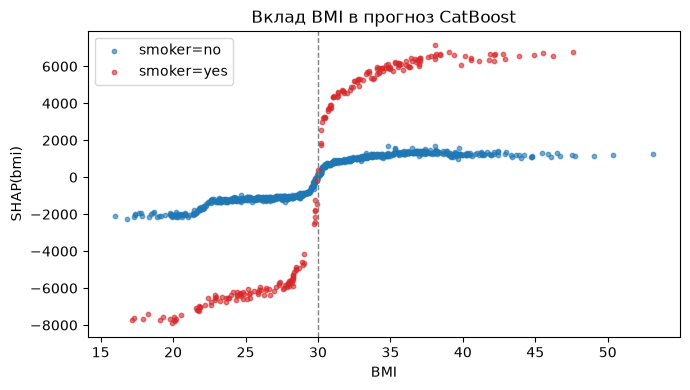

In [5]:
final_cb = CatBoostRegressor(**best_params, cat_features=CAT, random_seed=SEED, verbose=0).fit(X_train, y_train)
train_pool = Pool(X_train, cat_features=CAT)

shap_values = final_cb.get_feature_importance(train_pool, type="ShapValues")[:, :-1]
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=X_train.columns).sort_values(ascending=False)
print("Средний |SHAP|, у.е. charges:")
print(mean_abs.round(0).to_string())

names = list(X_train.columns)
interactions = np.abs(final_cb.get_feature_importance(train_pool, type="ShapInteractionValues")[:, :-1, :-1]).mean(axis=0)
pairs = pd.Series({f"{names[i]} × {names[j]}": 2 * interactions[i, j]
                   for i in range(len(names)) for j in range(i + 1, len(names))}).sort_values(ascending=False)
print("\nСредний |SHAP interaction|, у.е. charges:")
print(pairs.head(4).round(0).to_string())

bmi_idx = names.index("bmi")
fig, ax = plt.subplots(figsize=(7, 4))
for status, color in [("no", "tab:blue"), ("yes", "tab:red")]:
    mask = (X_train["smoker"] == status).to_numpy()
    ax.scatter(X_train.loc[mask, "bmi"], shap_values[mask, bmi_idx], s=10, alpha=0.6, c=color, label=f"smoker={status}")
ax.axvline(30, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("BMI")
ax.set_ylabel("SHAP(bmi)")
ax.set_title("Вклад BMI в прогноз CatBoost")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "boosting_shap_bmi.png", dpi=120)
plt.show()

По среднему |SHAP| первыми идут smoker, age и bmi; sex и region — последние. Взаимодействие bmi × smoker примерно в десять раз больше остальных. Около BMI = 30 вклад BMI меняется примерно на 11 тыс. у курящих и на 2 тыс. у некурящих.

## 5. Признаки для линейной модели

По EDA и SHAP добавлены:

- `obese`: BMI ≥ 30;
- `smoker_obese`: курит и BMI ≥ 30;
- `age2`: квадрат возраста.

Признаки выбраны на train и вычисляются построчно, без статистик других объектов.

In [6]:
def add_features(X):
    X = X.copy()
    X["obese"] = (X["bmi"] >= 30).astype(int)
    X["smoker_obese"] = ((X["smoker"] == "yes") & (X["bmi"] >= 30)).astype(int)
    X["age2"] = X["age"] ** 2
    return X


NUM_FE = NUM + ["obese", "smoker_obese", "age2"]
ols_fe = cv_rmse(lambda: linear(NUM_FE), X_train, y_train, add_features)
print(f"OLS:              CV RMSE {cv_table['OLS'][0]:.1f} ± {cv_table['OLS'][1]:.1f}")
print(f"OLS + 3 признака: CV RMSE {ols_fe[0]:.1f} ± {ols_fe[1]:.1f}")
print(f"CatBoost Optuna:  CV RMSE {best.value:.1f}")

OLS:              CV RMSE 6123.4 ± 491.6
OLS + 3 признака: CV RMSE 4448.2 ± 638.8
CatBoost Optuna:  CV RMSE 4532.0


CV RMSE OLS с тремя признаками — 4448 против 6123 без них. У CatBoost после Optuna — 4532.

## 6. Отбор признаков

CV RMSE с `sex` и `region` и без них.

In [7]:
SMALL_NUM, SMALL_CAT = NUM_FE, ["smoker"]
ols_small = cv_rmse(lambda: linear(SMALL_NUM, SMALL_CAT), X_train, y_train,
                    lambda X: add_features(X)[SMALL_NUM + SMALL_CAT])
cb_small = catboost_cv(best.params, X_train.drop(columns=["sex", "region"]), cat=["smoker"])

pd.DataFrame({
    "все признаки": [ols_fe[0], best.value],
    "без sex и region": [ols_small[0], cb_small[0]],
}, index=["OLS + 3 признака", "CatBoost Optuna"]).round(1)

,все признаки,без sex и region
OLS + 3 признака,4448.2,4471.1
CatBoost Optuna,4532.0,4561.5


Удаление sex и region меняет CV RMSE на 20–30 при стандартном отклонении по folds около 600. В финальных моделях оставлен полный набор.

## 7. Регрессия: финальная проверка на test

Все модели обучены на полном train с выбранными по CV параметрами.

In [8]:
ols = linear().fit(X_train, y_train)
ols_fe_model = linear(NUM_FE).fit(add_features(X_train), y_train)
cb_default = CatBoostRegressor(cat_features=CAT, random_seed=SEED, verbose=0).fit(X_train, y_train)

predictions = {
    "OLS": ols.predict(X_test),
    "OLS + 3 признака": ols_fe_model.predict(add_features(X_test)),
    "CatBoost по умолчанию": cb_default.predict(X_test),
    "CatBoost Optuna": final_cb.predict(X_test),
}
reg_metrics = pd.DataFrame({
    name: {"RMSE": rmse(y_test, p), "MAE": mean_absolute_error(y_test, p), "R2": r2_score(y_test, p)}
    for name, p in predictions.items()
}).T
reg_metrics.round({"RMSE": 1, "MAE": 1, "R2": 4}).to_csv(RESULTS / "boosting_regression_metrics.csv",
                                                          index_label="model")
reg_metrics.round({"RMSE": 1, "MAE": 1, "R2": 4})

,RMSE,MAE,R2
OLS,5796.3,4181.2,0.7836
OLS + 3 признака,4364.3,2390.4,0.8773
CatBoost по умолчанию,4395.6,2524.8,0.8755
CatBoost Optuna,4275.5,2413.4,0.8823


Test: R² OLS вырос с 0,7836 до 0,8773 после добавления признаков. CatBoost после Optuna: R² 0,8823, RMSE 4276, MAE 2413. В test 268 строк.

## 8. Классификация: дорогие клиенты

Положительный класс: `charges` не ниже 80-го перцентиля train, около 20% клиентов. Оцениваем ROC-AUC и PR-AUC. Для precision, recall и F1 порог вероятности выбирается по максимальному F1 на OOF-предсказаниях train. Базовое правило: «курит → дорогой клиент».

In [9]:
cost_threshold = y_train.quantile(0.8)
yb_train = (y_train >= cost_threshold).astype(int)
yb_test = (y_test >= cost_threshold).astype(int)
print(f"порог charges: {cost_threshold:.0f}; доля класса 1: train {yb_train.mean():.2f}, test {yb_test.mean():.2f}")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def logreg(num=NUM):
    return linear(num, CAT, model=lambda: LogisticRegression(max_iter=1000))


classifiers = {
    "LogReg": (logreg, lambda X: X),
    "LogReg + 3 признака": (lambda: logreg(NUM_FE), add_features),
    "CatBoost": (lambda: CatBoostClassifier(cat_features=CAT, random_seed=SEED, verbose=0), lambda X: X),
}


def oof_proba(make_model, prep):
    oof = np.zeros(len(yb_train))
    for tr, va in skf.split(X_train, yb_train):
        model = make_model().fit(prep(X_train.iloc[tr]), yb_train.iloc[tr])
        oof[va] = model.predict_proba(prep(X_train.iloc[va]))[:, 1]
    return oof


oof = {"Только smoker": (X_train["smoker"] == "yes").astype(float).to_numpy()}
oof |= {name: oof_proba(make, prep) for name, (make, prep) in classifiers.items()}

pd.DataFrame({name: {"ROC-AUC": roc_auc_score(yb_train, p), "PR-AUC": average_precision_score(yb_train, p)}
              for name, p in oof.items()}).T.round(4)

порог charges: 20153; доля класса 1: train 0.20, test 0.21


,ROC-AUC,PR-AUC
Только smoker,0.8534,0.6241
LogReg,0.8883,0.8410
LogReg + 3 признака,0.8939,0.8479
CatBoost,0.8843,0.8454


У правила «курит» ROC-AUC 0,85 и PR-AUC 0,62. У LogReg и CatBoost PR-AUC 0,84–0,85.

LogReg: порог 0.567, OOF F1 0.8080
LogReg + 3 признака: порог 0.473, OOF F1 0.8377
CatBoost: порог 0.385, OOF F1 0.8372


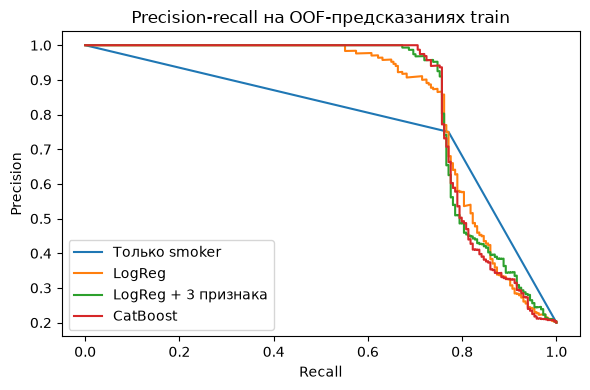

In [10]:
def best_f1_threshold(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    i = np.argmax(f1[:-1])
    return thresholds[i], f1[i]


fig, ax = plt.subplots(figsize=(6, 4))
thresholds = {}
for name, p in oof.items():
    precision, recall, _ = precision_recall_curve(yb_train, p)
    ax.plot(recall, precision, label=name)
    if name in classifiers:
        thresholds[name], f1_oof = best_f1_threshold(yb_train, p)
        print(f"{name}: порог {thresholds[name]:.3f}, OOF F1 {f1_oof:.4f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall на OOF-предсказаниях train")
ax.legend()
fig.tight_layout()
plt.show()

OOF F1 максимален при пороге 0,385 у CatBoost и 0,473 у LogReg с признаками, а не при 0,5. Эти пороги используются на test без изменения.

## 9. Классификация: финальная проверка на test

In [11]:
rows = {}
smoker_rule = (X_test["smoker"] == "yes").astype(int)
rows["Только smoker"] = {"ROC-AUC": roc_auc_score(yb_test, smoker_rule),
                         "PR-AUC": average_precision_score(yb_test, smoker_rule),
                         "threshold": np.nan,
                         "precision": precision_score(yb_test, smoker_rule),
                         "recall": recall_score(yb_test, smoker_rule),
                         "F1": f1_score(yb_test, smoker_rule)}
for name, (make, prep) in classifiers.items():
    proba = make().fit(prep(X_train), yb_train).predict_proba(prep(X_test))[:, 1]
    pred = (proba >= thresholds[name]).astype(int)
    rows[name] = {"ROC-AUC": roc_auc_score(yb_test, proba), "PR-AUC": average_precision_score(yb_test, proba),
                  "threshold": thresholds[name], "precision": precision_score(yb_test, pred),
                  "recall": recall_score(yb_test, pred), "F1": f1_score(yb_test, pred)}

clf_metrics = pd.DataFrame(rows).T.round(4)
clf_metrics.to_csv(RESULTS / "boosting_classification_metrics.csv", index_label="model")
clf_metrics

,ROC-AUC,PR-AUC,threshold,precision,recall,F1
Только smoker,0.8734,0.7027,NaN,0.8333,0.7895,0.8108
LogReg,0.9090,0.8763,0.5670,0.9362,0.7719,0.8462
LogReg + 3 признака,0.9199,0.8862,0.4725,1.0000,0.7544,0.8600
CatBoost,0.9135,0.8770,0.3855,0.9778,0.7719,0.8627


Test, CatBoost / LogReg с признаками: F1 0,863 / 0,860; precision 0,98 / 1,0; recall 0,77 / 0,75.

## Ограничения

1338 строк, один test, нет временной разметки. Значимость разницы между моделями не проверялась.